# Desafio: K-Means do zero
**Objetivo:** agrupar clientes por frequência de compras e gasto médio, sem receber rótulos de resposta durante o treinamento.

## 1. Criar o dataset sintético
Geramos os mesmos 150 clientes do exercício guiado, com duas características em `X`. Não criamos respostas `y`: os grupos serão encontrados pelo algoritmo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def uniformes(n, semente):
    i = np.arange(1, n + 1)
    v = np.sin(i * 12.9898 + semente * 78.233) * 43758.5453
    return v - np.floor(v)


def ruido_normal(n, semente):
    u = uniformes(3 * n, semente).reshape(3, n)
    return (u.sum(axis=0) - 1.5) * 2


#criando os dados
centros = np.array([[2.0, 60.0], [9.0, 75.0], [4.5, 260.0]])
desvios = np.array([[0.6, 15.0], [1.0, 18.0], [0.9, 35.0]])
n = 50
blocos = []

for g in range(3):
    s = 10 * g
    freq = centros[g, 0] + desvios[g, 0] * ruido_normal(n, s + 1)
    gasto = centros[g, 1] + desvios[g, 1] * ruido_normal(n, s + 2)
    blocos.append(np.column_stack([freq, gasto]))

X = np.vstack(blocos)
print(X.shape)
print(X[:3].round(1))

(150, 2)
[[ 1.7 38.9]
 [ 1.7 49.5]
 [ 2.4 55.6]]


## 2. Padronizar os dados e definir K
Colocamos compras e gasto em escalas comparáveis para calcular as distâncias. Começamos com K = 3 e depois verificamos essa escolha pelo cotovelo.

In [2]:
media = X.mean(axis=0)
desvio = X.std(axis=0)
desvio = np.where(desvio == 0, 1.0, desvio)
X_esc = (X - media) / desvio
K = 3

print("Média após padronizar:", X_esc.mean(axis=0).round(3))
print("Desvio após padronizar:", X_esc.std(axis=0).round(3))

Média após padronizar: [ 0. -0.]
Desvio após padronizar: [1. 1.]


## 3. Inicializar centros, calcular distâncias e atribuir grupos
A inicialização escolhe K amostras como centros. Cada ponto recebe o índice do centro mais próximo; usamos distâncias ao quadrado, que preservam a escolha do mais próximo.

In [3]:
def inicializar_centroides(X, K, semente):
    indices = np.argsort(uniformes(len(X), semente))[:K]
    return X[indices].copy()


def calcular_distancias(X, centroides):
    diferencas = X[:, None, :] - centroides[None, :, :]
    return np.sum(diferencas ** 2, axis=2)


def atribuir_clusters(distancias):
    return np.argmin(distancias, axis=1)

## 4. Atualizar centros e tratar grupos vazios
Cada centro se move para a média do seu grupo. Se o grupo estiver vazio, reposicionamos seu centro em um ponto distante do centro que o atende, evitando a média de um conjunto vazio.

In [4]:
def atualizar_centroides(X, labels, centroides, distancias):
    novos = centroides.copy()
    d_atual = distancias[np.arange(len(X)), labels].copy()

    for k in range(len(centroides)):
        pontos = X[labels == k]
        if len(pontos) > 0:
            novos[k] = pontos.mean(axis=0)
        else:
            mais_longe = np.argmax(d_atual)
            novos[k] = X[mais_longe]
            d_atual[mais_longe] = -1.0

    return novos

## 5. Implementar a classe KMeansDoZero
`fit` repete atribuições e atualizações até o deslocamento ficar dentro de `tol` ou atingir `max_iter`. Ao final, recalculamos os rótulos e a inércia com os centros finais; `predict` usa esses centros em pontos novos.

In [5]:
class KMeansDoZero:
    def __init__(self, n_clusters=3, max_iter=100, tol=1e-4, random_state=0):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if not 1 <= self.n_clusters <= len(X):
            raise ValueError("n_clusters deve estar entre 1 e o número de amostras")
        if self.max_iter < 1:
            raise ValueError("max_iter deve ser >= 1")

        C = inicializar_centroides(X, self.n_clusters, self.random_state)
        self.historico_centroides_ = [C.copy()]
        self.historico_inercia_ = []

        for it in range(1, self.max_iter + 1):
            D = calcular_distancias(X, C)
            labels = atribuir_clusters(D)
            J = D[np.arange(len(X)), labels].sum()
            self.historico_inercia_.append(J)

            novos = atualizar_centroides(X, labels, C, D)
            desloc = np.sqrt(((novos - C) ** 2).sum(axis=1)).max()
            C = novos
            self.historico_centroides_.append(C.copy())
            if desloc <= self.tol:
                break

        D = calcular_distancias(X, C)
        self.centroides_ = C
        self.labels_ = atribuir_clusters(D)
        self.inercia_ = D[np.arange(len(X)), self.labels_].sum()
        self.historico_inercia_.append(self.inercia_)
        self.n_iter_ = it
        return self

    def predict(self, X):
        if not hasattr(self, "centroides_"):
            raise RuntimeError("chame fit() antes de predict()")
        D = calcular_distancias(np.asarray(X, dtype=float), self.centroides_)
        return atribuir_clusters(D)

    def fit_predict(self, X):
        return self.fit(X).labels_

## 6. Treinar e mostrar os centroides finais
Treinamos com os dados padronizados e mostramos o tamanho dos grupos. Desfazemos a padronização dos centros para interpretá-los em compras por mês e reais.

In [6]:
modelo = KMeansDoZero(n_clusters=K, random_state=42)
modelo.fit(X_esc)
centros_originais = modelo.centroides_ * desvio + media
tamanhos = np.bincount(modelo.labels_, minlength=K)

print("Iterações:", modelo.n_iter_)
print("Inércia:", round(modelo.inercia_, 3))
print("Clientes por grupo:", tamanhos)
print("Centroides finais: compras por mês e gasto médio (R$)")
print(centros_originais.round(2))

Iterações: 3
Inércia: 21.581
Clientes por grupo: [50 50 50]
Centroides finais: compras por mês e gasto médio (R$)
[[  9.31  74.79]
 [  4.39 255.19]
 [  2.03  61.92]]


## 7. Visualizar os grupos
Cada cor representa um grupo encontrado. Os X marcam os centroides nas unidades originais, permitindo relacionar cada grupo ao comportamento de compra.

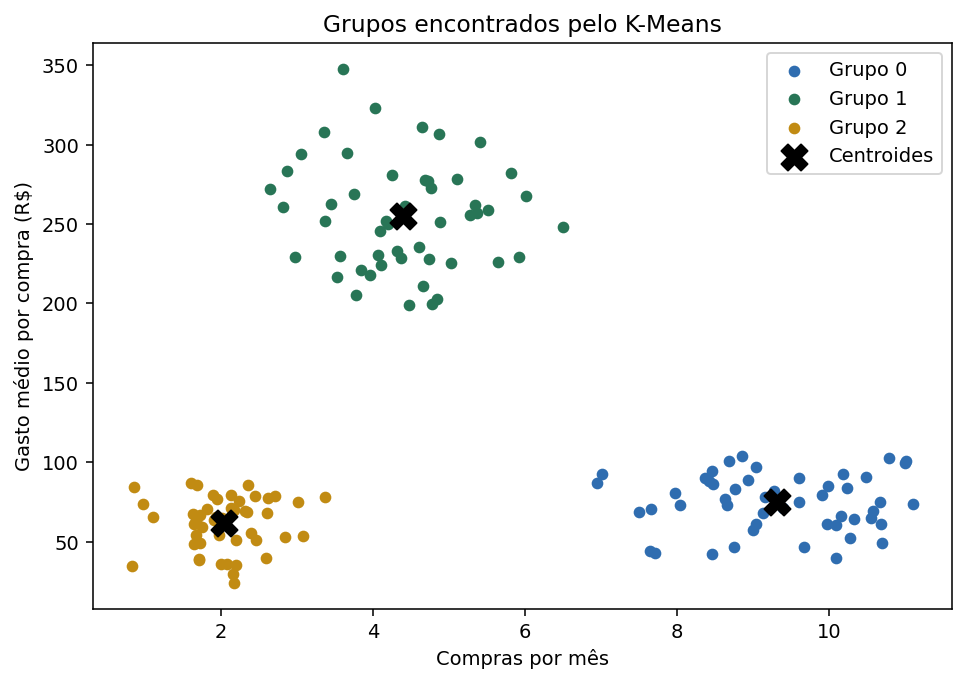

In [7]:
cores = ["#2F6DB0", "#287556", "#C18B13"]
plt.figure(figsize=(7, 5))
for grupo in range(K):
    pontos = X[modelo.labels_ == grupo]
    plt.scatter(pontos[:, 0], pontos[:, 1], color=cores[grupo], s=25, label=f"Grupo {grupo}")
plt.scatter(centros_originais[:, 0], centros_originais[:, 1], marker="X",
            s=180, color="black", label="Centroides")
plt.xlabel("Compras por mês")
plt.ylabel("Gasto médio por compra (R$)")
plt.title("Grupos encontrados pelo K-Means")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Mostrar a evolução da inércia
A inércia soma as distâncias ao quadrado dos pontos aos centros dos seus grupos. O gráfico mostra essa medida no início e após as atualizações.

Histórico da inércia: [223.83   54.205  21.581  21.581]


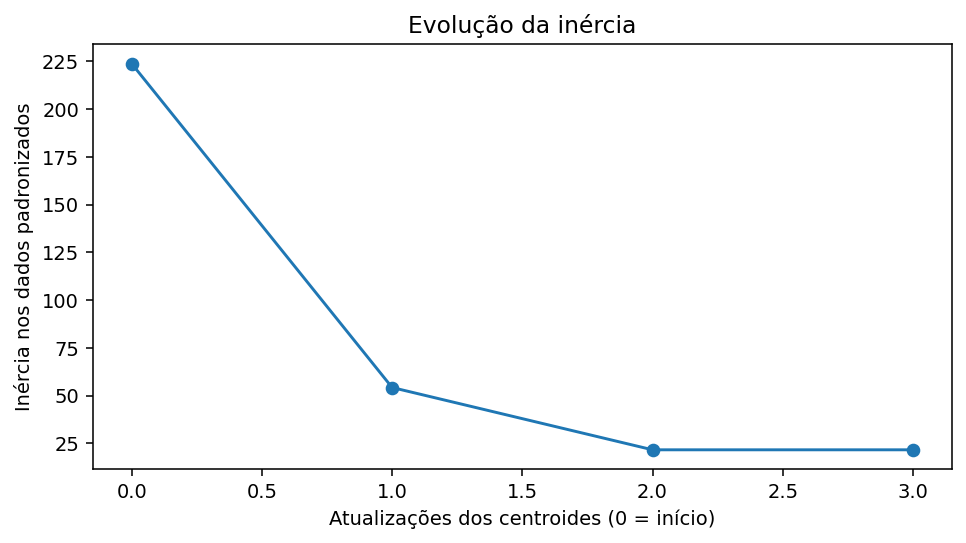

In [8]:
print("Histórico da inércia:", np.round(modelo.historico_inercia_, 3))

plt.figure(figsize=(7, 4))
plt.plot(range(len(modelo.historico_inercia_)), modelo.historico_inercia_, marker="o")
plt.xlabel("Atualizações dos centroides (0 = início)")
plt.ylabel("Inércia nos dados padronizados")
plt.title("Evolução da inércia")
plt.tight_layout()
plt.show()

## 9. Aplicar o método do cotovelo
Experimentamos K de 1 a 8, guardando a menor inércia entre dez inicializações para cada K. Procuramos onde a queda perde força; a menor inércia isolada não define a melhor quantidade de grupos.

K: [1, 2, 3, 4, 5, 6, 7, 8]
Inércias: [300.   147.4   21.58  16.93  12.45  10.19   9.11   8.33]


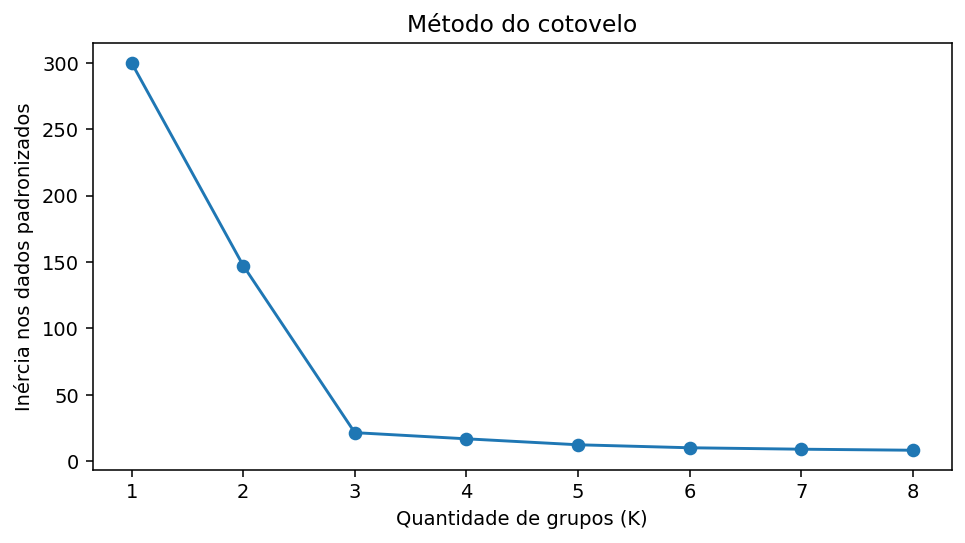

In [9]:
valores_K = range(1, 9)
inercias = []

for k in valores_K:
    melhor_inercia = min(
        KMeansDoZero(k, random_state=semente).fit(X_esc).inercia_
        for semente in range(10)
    )
    inercias.append(melhor_inercia)

print("K:", list(valores_K))
print("Inércias:", np.round(inercias, 2))

plt.figure(figsize=(7, 4))
plt.plot(valores_K, inercias, marker="o")
plt.xlabel("Quantidade de grupos (K)")
plt.ylabel("Inércia nos dados padronizados")
plt.title("Método do cotovelo")
plt.xticks(list(valores_K))
plt.tight_layout()
plt.show()

## 10. Comparar sementes
Mudamos o sorteio inicial mantendo os dados e K. A comparação mostra que uma execução pode parar em uma solução de inércia maior; as dez inicializações ajudam a procurar uma solução melhor.

In [10]:
for semente in [42, 1, 7]:
    m = KMeansDoZero(K, random_state=semente).fit(X_esc)
    print(
        f"Semente {semente}: inércia = {m.inercia_:.3f} | "
        f"iterações = {m.n_iter_} | "
        f"tamanhos = {np.bincount(m.labels_, minlength=K)}"
    )

tentativas = [KMeansDoZero(K, random_state=s).fit(X_esc) for s in range(10)]
melhor = min(tentativas, key=lambda m: m.inercia_)
print("Melhor inércia entre dez sementes:", round(melhor.inercia_, 3))

Semente 42: inércia = 21.581 | iterações = 3 | tamanhos = [50 50 50]
Semente 1: inércia = 150.566 | iterações = 9 | tamanhos = [100  29  21]
Semente 7: inércia = 21.581 | iterações = 2 | tamanhos = [50 50 50]
Melhor inércia entre dez sementes: 21.581


## 11. Comparar com o scikit-learn
Comparamos os mesmos dados padronizados e K, alinhando os centros antes de comparar os identificadores dos grupos. A concordância mede a semelhança entre as duas implementações, não acurácia contra respostas conhecidas.

In [11]:
from sklearn.cluster import KMeans

sk = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_esc)
par = atribuir_clusters(calcular_distancias(modelo.centroides_, sk.cluster_centers_))
diferenca = np.abs(modelo.centroides_ - sk.cluster_centers_[par]).max()
concordancia = (par[modelo.labels_] == sk.labels_).mean()

print("Inércia da nossa implementação:", round(modelo.inercia_, 3))
print("Inércia do scikit-learn:", round(sk.inertia_, 3))
print("Maior diferença entre centros pareados:", round(diferenca, 6))
print("Concordância após pareamento:", concordancia)

Inércia da nossa implementação: 21.581
Inércia do scikit-learn: 21.581
Maior diferença entre centros pareados: 0.0
Concordância após pareamento: 1.0


## 12. Interpretar os resultados
As médias estão nas unidades originais. Os identificadores dos grupos não indicam uma ordem de importância.

| Grupo | Clientes | Compras por mês | Gasto médio por compra |
|---|---:|---:|---:|
| 0 | 50 | 9,31 | R$ 74,79 |
| 1 | 50 | 4,39 | R$ 255,19 |
| 2 | 50 | 2,03 | R$ 61,92 |

O grupo 0 reúne clientes de maior frequência de compras; o grupo 1, os de maior gasto médio por compra; e o grupo 2, os de menor frequência. A queda da inércia perde força depois de K = 3, apoiando essa escolha neste dataset. A inicialização com semente 1 produziu inércia maior, enquanto nossa execução principal coincidiu com o agrupamento do scikit-learn após o pareamento. Esses perfis descrevem os dados sintéticos utilizados; uma aplicação real exigiria avaliar seu sentido no contexto.